# 02 · VECM with imposed β — who error-corrects

The triangle identity fixes the cointegrating vector, so we impose β=(1,−1,−1) and
estimate only the adjustment loadings α. The leg with α≈0 doesn't error-correct — that's
the discovery leader. Prior: dollar legs lead, cross adjusts.

In [1]:
%load_ext autoreload
%autoreload 2

import datetime as dt
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fxpd.config import TRIANGLES, OUTPUTS_DIR, ensure_dirs
from fxpd.data.basis import build_panel
from fxpd.data.clean import run_qc, CLEAN_VERSION
from fxpd.econo.vecm import (
    TRIVARIATE, BIVARIATE,
    make_frame, select_k_bic, fit_windows, aggregate_windows,
)

ensure_dirs()
warnings.simplefilter("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## Parameters — tweak these

In [2]:
TRIANGLE = "majors"
START    = dt.date(2026, 5, 18)
END      = dt.date(2026, 6, 19)
FREQ     = "1s"
LIQUID   = (7, 17)
K        = None
N_BIC_WINDOWS, K_MAX = 20, 20

tri = TRIANGLES[TRIANGLE]
dates = list(pd.bdate_range(START, END).date)
bar_seconds = pd.Timedelta(FREQ).total_seconds()
print(f"{tri} | {len(dates)} business days | {FREQ} grid, liquid {LIQUID} UTC")

Triangle(name='majors', cross='EURJPY', leg1='EURUSD', leg2='USDJPY') | 25 business days | 1s grid, liquid (7, 17) UTC


## 1 · Data quality (cleaning QC)

In [3]:
qc = run_qc(list(tri.legs), START, END)
drop_cols = ["n_validity", "n_crossed", "n_spread", "n_spike"]
qc["drop_pct"] = 100 * qc[drop_cols].sum(axis=1) / qc["n_input"]
print(f"{len(qc)} instrument-days | worst drop rate {qc.drop_pct.max():.3f}% "
      f"| crossed-share flags: {int(qc.crossed_share_flag.sum())}")
qc.groupby("instrument")[["n_input", *drop_cols, "drop_pct",
                          "spread_p50_bp", "spread_p95_bp", "max_gap_s"]].agg(
    {"n_input": "sum", "n_validity": "sum", "n_crossed": "sum", "n_spread": "sum",
     "n_spike": "sum", "drop_pct": "mean", "spread_p50_bp": "median",
     "spread_p95_bp": "median", "max_gap_s": "max"})

87 instrument-days | worst drop rate 1.288% | crossed-share flags: 0


,n_input,n_validity,n_crossed,n_spread,n_spike,drop_pct,spread_p50_bp,spread_p95_bp,max_gap_s
instrument,,,,,,,,,
EURJPY,3668983,0,0,3076,51,0.08184,0.4847,0.7025,1242
EURUSD,1599413,0,0,2865,46,0.1974,0.2584,0.4333,1497
USDJPY,1448287,0,0,1619,81,0.1119,0.251,0.4981,1501


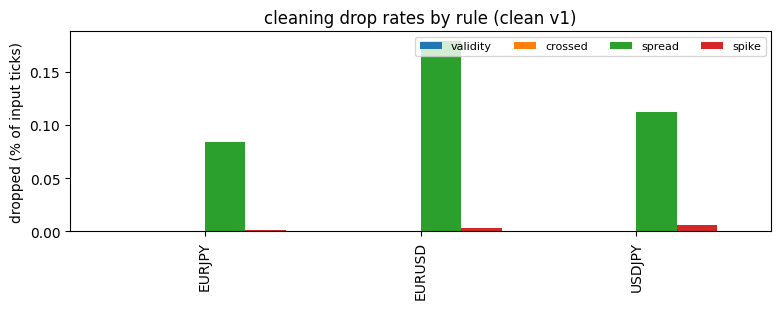

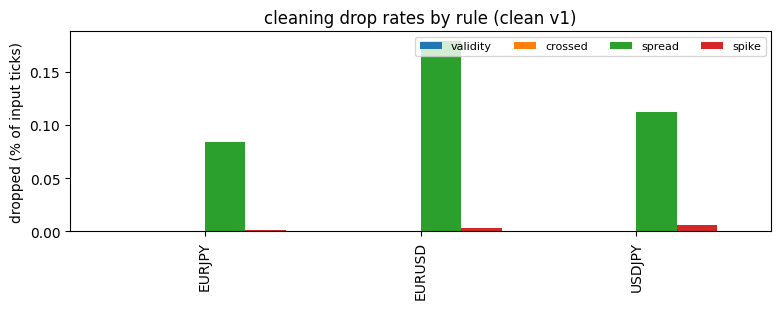

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
per_rule = qc.groupby("instrument")[drop_cols].sum()
(100 * per_rule.div(qc.groupby("instrument")["n_input"].sum(), axis=0)).plot.bar(
    ax=ax, width=0.75)
ax.set_ylabel("dropped (% of input ticks)"); ax.set_xlabel("")
ax.set_title(f"cleaning drop rates by rule (clean {CLEAN_VERSION})")
ax.legend([c.removeprefix("n_") for c in drop_cols], ncol=4, fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUTS_DIR / "02_qc_drops.png", dpi=130)
fig

## 2 · Lag selection (BIC, common effective sample)

In [5]:
bic_rows = []
for d in dates:
    if len(bic_rows) >= N_BIC_WINDOWS:
        break
    try:
        panel = build_panel(tri, d, d, FREQ, with_age=True)
    except FileNotFoundError:
        continue
    h = panel.index.hour
    win = panel[(h >= LIQUID[0]) & (h < LIQUID[1])]
    if len(win) < 5000:
        continue
    b = select_k_bic(make_frame(win, tri, TRIVARIATE), k_max=K_MAX)
    b["date"] = d
    bic_rows.append(b)

bic = pd.concat(bic_rows, ignore_index=True)
k_star = bic.loc[bic.groupby("date")["bic"].idxmin()]
K_USED = int(K if K is not None else k_star["k"].mode().iloc[0])
print(f"modal k over {len(bic_rows)} windows -> K_USED = {K_USED}")

modal k over 20 windows -> K_USED = 5


## 3 · Result 1 — α loadings across windows (trivariate)

In [6]:
res_tri = fit_windows(tri, dates, FREQ, K_USED, TRIVARIATE, liquid=LIQUID)
print(f"{len(res_tri)} windows estimated, {res_tri.attrs['skipped']} skipped")
agg_tri = aggregate_windows(res_tri)
agg_tri

25 windows estimated, 0 skipped


,alpha_median,alpha_q25,alpha_q75,share_|t|>1.96,lb_pass_rate,n_windows
series,,,,,,
EURJPY,-0.07917,-0.1078,-0.05936,1,0.56,25
EURUSD,0.07946,0.06601,0.09036,1,0.4,25
USDJPY,0.06026,0.05513,0.07652,0.92,0.08,25


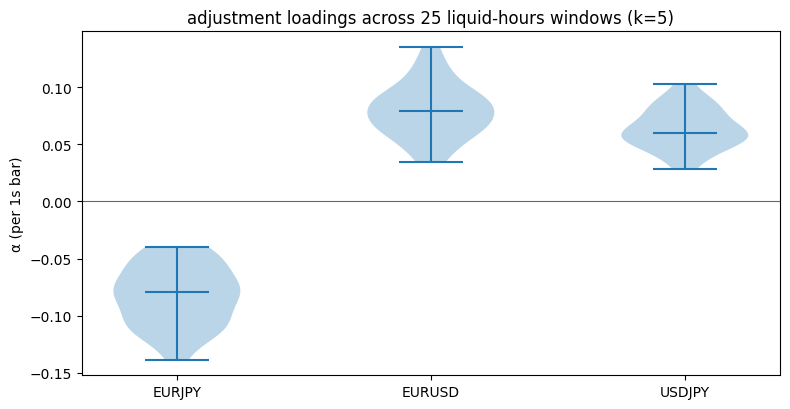

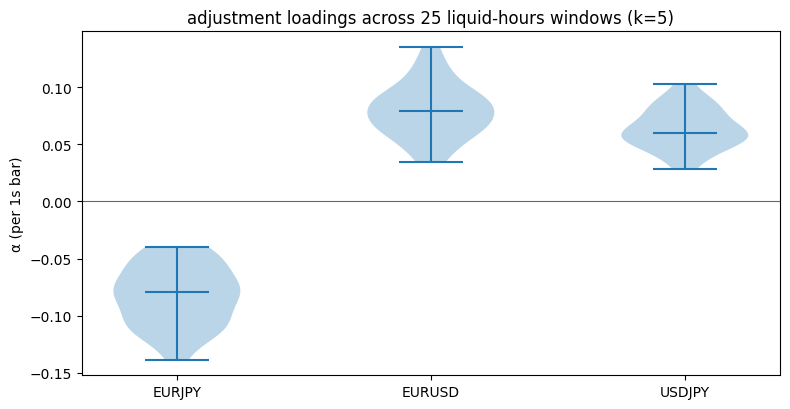

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
series = [res_tri[f"alpha_{n}"].dropna() for n in tri.legs]
vp = ax.violinplot(series, showmedians=True)
ax.axhline(0, color="k", lw=0.8, alpha=0.6)
ax.set_xticks(range(1, 4), tri.legs)
ax.set_ylabel(f"α (per {FREQ} bar)")
ax.set_title(f"adjustment loadings across {len(res_tri)} liquid-hours windows (k={K_USED})")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR / "02_alpha_violin.png", dpi=130)
fig

## 4 · Result 2 — half-life of the basis

half-life (s): median 2.7  IQR [2.3, 3.0]  n=25/25 windows valid


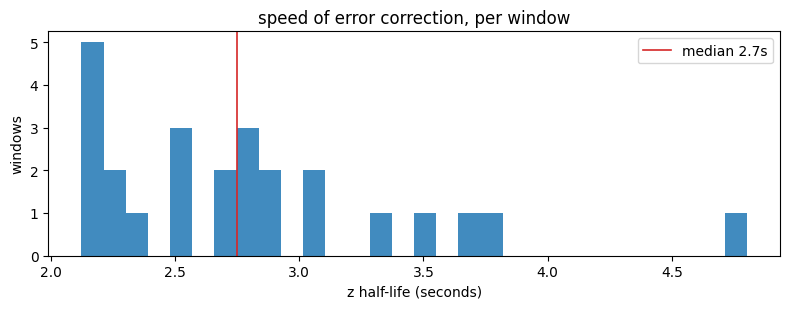

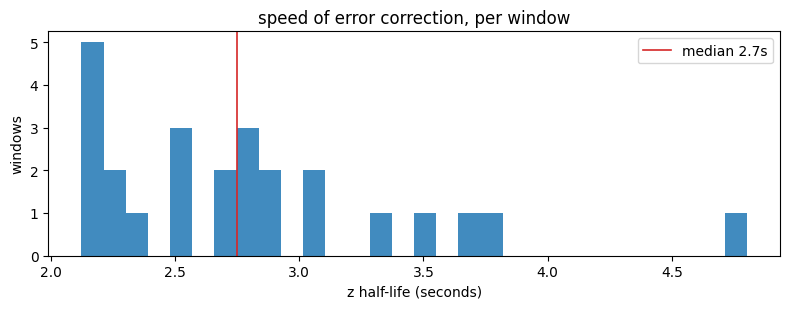

In [8]:
hl = res_tri["half_life_s"].dropna()
print(f"half-life (s): median {hl.median():.1f}  IQR [{hl.quantile(.25):.1f}, "
      f"{hl.quantile(.75):.1f}]  n={len(hl)}/{len(res_tri)} windows valid")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(hl, bins=30, color="tab:blue", alpha=0.85)
ax.axvline(hl.median(), color="tab:red", lw=1.2, label=f"median {hl.median():.1f}s")
ax.set_xlabel("z half-life (seconds)"); ax.set_ylabel("windows"); ax.legend()
ax.set_title("speed of error correction, per window")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR / "02_halflife_hist.png", dpi=130)
fig

## 5 · Staleness robustness

In [9]:
res_tri_f = fit_windows(tri, dates, FREQ, K_USED, TRIVARIATE,
                        liquid=LIQUID, stale_filter=True)
cmp = pd.concat({
    "all bars": aggregate_windows(res_tri)[["alpha_median", "share_|t|>1.96"]],
    "fresh z_{t-1} only": aggregate_windows(res_tri_f)[["alpha_median", "share_|t|>1.96"]],
}, axis=1)
mean_fresh = res_tri[[f"fresh_{n}" for n in tri.legs]].mean().rename("mean fresh share")
display(cmp)
mean_fresh.to_frame().T

all bars                fresh z_{t-1} only               
       alpha_median share_|t|>1.96       alpha_median share_|t|>1.96
series                                                              
EURJPY     -0.07917              1            -0.0875              1
EURUSD      0.07946              1            0.08206              1
USDJPY      0.06026           0.92            0.06606           0.88

,fresh_EURJPY,fresh_EURUSD,fresh_USDJPY
mean fresh share,0.6904,0.458,0.3894


## 6 · Bivariate preview (cross vs synthetic) — feeds Week 3

In [10]:
res_bi = fit_windows(tri, dates, FREQ, K_USED, BIVARIATE, liquid=LIQUID)
agg_bi = aggregate_windows(res_bi)
hl_bi = res_bi["half_life_s"].dropna()
print(f"bivariate half-life: median {hl_bi.median():.1f}s "
      f"IQR [{hl_bi.quantile(.25):.1f}, {hl_bi.quantile(.75):.1f}]")
agg_bi

bivariate half-life: median 2.7s IQR [2.3, 3.0]


,alpha_median,alpha_q25,alpha_q75,share_|t|>1.96,lb_pass_rate,n_windows
series,,,,,,
EURJPY,-0.07998,-0.1106,-0.06297,1,0.52,25
synth,0.1443,0.1236,0.162,1,0.52,25


## Takeaway

25 liquid-hours windows, 1 s, k=5. Every leg error-corrects with the expected signs: when z>0 the
cross falls (α≈−0.079 [IQR −0.108, −0.059]) and the dollar legs rise (+0.079, +0.060); |t|>1.96
in ≥92% of windows. The AR(1) **half-life proxy** is ~2.7 s (IQR 2.3–3.0); it ignores the lag
dynamics Γ and understates — the dynamic first-passage half-life is ~8 s (03). Bivariate: synth
adjusts ~1.8× the cross → GG preview ≈0.64 on the quoted cross, mildly against the "dollar legs
lead" prior (on this grid; the staleness controls in 07 bring the full-sample share to ~0.57).

Caveats: LOCF staleness (fresh-only *strengthens* every α → attenuation toward 0); Ljung–Box passes
in only 56/40/8% of windows, so all inference is HAC; quote-based aggregator feed, no trades.